# Husleje ud fra boligareal med lineær regression

*Sammenligningsøvelse, del 1 af 2. Del 2 er den lokale LLM med RAG i [`../experiment_rag/llm_rag.ipynb`](../experiment_rag/llm_rag.ipynb).*

**Resumé.** Vi estimerer den annoncerede månedlige husleje for en københavnsk lejlighed ud fra arealet med en lineær regression. Modellen tilpasses 294 træningsrækker og testes på de samme seks testcases som LLM + RAG i del 2. Den finder ca. 139 kr. pr. m² plus 4.868 kr. og opnår en MAE på 976 kr. Regressionen er dermed baseline i sammenligningen.

Input er `area_m2`, og target er `monthly_rent_dkk`. En række er én lejlighed. `dataset.csv` har 300 rækker:

- **10 rigtige annoncer** (`data_type=real`) fra [BoligPortals liste over lejligheder i København](https://www.boligportal.dk/lejligheder/k%C3%B8benhavn/) ved opslag 23. november 2026. Linket til hver annonce står i `source_url`. Lejen er den annoncerede månedlige husleje. Særskilt aconto, depositum og forudbetalt husleje indgår ikke. Annoncer kan udløbe.
- **290 genererede rækker** (`data_type=synthetic`) uden link. De følger samme sammenhæng mellem areal og leje som de rigtige annoncer. Se `README.md`.

Kolonnen `split` deler data i 294 træningsrækker og 6 testrækker. Testrækkerne er de 2 rigtige testannoncer og 4 genererede rækker spredt over arealerne. Del 2 bruger det samme split.

## 1. Læs data

`X` er input. `y` er værdien, vi vil forudsige.

In [1]:
import csv
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

DATA_DIR = Path.cwd()

with (DATA_DIR / "dataset.csv").open(encoding="utf-8", newline="") as dataset:
    rows = list(csv.DictReader(dataset))

train = [row for row in rows if row["split"] == "train"]
test = [row for row in rows if row["split"] == "test"]

## 2. Brug det faste split

Vi deler ikke tilfældigt. Kolonnen `split` i CSV'en er den eneste kilde til delingen, så LLM + RAG får præcis de samme testinput. `y_test` bruges kun til at måle fejlen.

In [2]:
X_train = [[float(row["area_m2"])] for row in train]
y_train = [float(row["monthly_rent_dkk"]) for row in train]
X_test = [[float(row["area_m2"])] for row in test]
y_test = [float(row["monthly_rent_dkk"]) for row in test]

print(f"Træning: {len(X_train)} rækker")
print(f"Test: {len(X_test)} rækker")

Træning: 294 rækker
Test: 6 rækker


## 3. Træn og test

Modellen lærer af `X_train` og `y_train`. Den forudsiger på `X_test`. `y_test` bruges til at måle afvigelsen. MAE er gennemsnittet af de absolutte fejl i samme enhed som målværdien.

In [3]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Model: husleje = {model.intercept_:,.2f} + {model.coef_[0]:,.2f} * areal")

for (x,), actual, predicted in zip(X_test, y_test, predictions):
    print(f"X = {x:g} | Faktisk: {actual:,.2f} | Forudsagt: {predicted:,.2f}")

mae = mean_absolute_error(y_test, predictions)
print(f"MAE: {mae:,.2f}")

Model: husleje = 4,867.79 + 139.04 * areal
X = 85 | Faktisk: 14,500.00 | Forudsagt: 16,686.31
X = 117 | Faktisk: 20,486.00 | Forudsagt: 21,135.63
X = 99 | Faktisk: 16,550.00 | Forudsagt: 18,632.89
X = 141 | Faktisk: 24,900.00 | Forudsagt: 24,472.62
X = 60 | Faktisk: 13,600.00 | Forudsagt: 13,210.28
X = 31 | Faktisk: 9,300.00 | Forudsagt: 9,178.08
MAE: 976.31


In [4]:
from IPython.display import Markdown, display

def kroner(beløb):
    return f"{beløb:,.2f}".translate(str.maketrans(",.", ".,"))

rækker = [
    "| Boligareal | Type | Faktisk husleje | Forudsagt husleje | Absolut fejl |",
    "|---:|---|---:|---:|---:|",
]

for row, (areal,), faktisk, forudsagt in zip(test, X_test, y_test, predictions):
    fejl = abs(faktisk - forudsagt)
    type_ = "rigtig" if row["data_type"] == "real" else "genereret"
    rækker.append(
        f"| {areal:g} m² | {type_} | {kroner(faktisk)} kr. | "
        f"{kroner(forudsagt)} kr. | {kroner(fejl)} kr. |"
    )

rækker.append(f"| **MAE** | | | | **{kroner(mae)} kr.** |")

display(Markdown("### Testresultater for månedlig husleje\n\n" + "\n".join(rækker)))

### Testresultater for månedlig husleje

| Boligareal | Type | Faktisk husleje | Forudsagt husleje | Absolut fejl |
|---:|---|---:|---:|---:|
| 85 m² | rigtig | 14.500,00 kr. | 16.686,31 kr. | 2.186,31 kr. |
| 117 m² | rigtig | 20.486,00 kr. | 21.135,63 kr. | 649,63 kr. |
| 99 m² | genereret | 16.550,00 kr. | 18.632,89 kr. | 2.082,89 kr. |
| 141 m² | genereret | 24.900,00 kr. | 24.472,62 kr. | 427,38 kr. |
| 60 m² | genereret | 13.600,00 kr. | 13.210,28 kr. | 389,72 kr. |
| 31 m² | genereret | 9.300,00 kr. | 9.178,08 kr. | 121,92 kr. |
| **MAE** | | | | **976,31 kr.** |

## 4. Se regressionslinjen

De lyse punkter er alle træningsrækker. De mørke er de rigtige træningsannoncer. De stiplede stræk viser afstanden fra forudsigelse til den faktiske værdi.

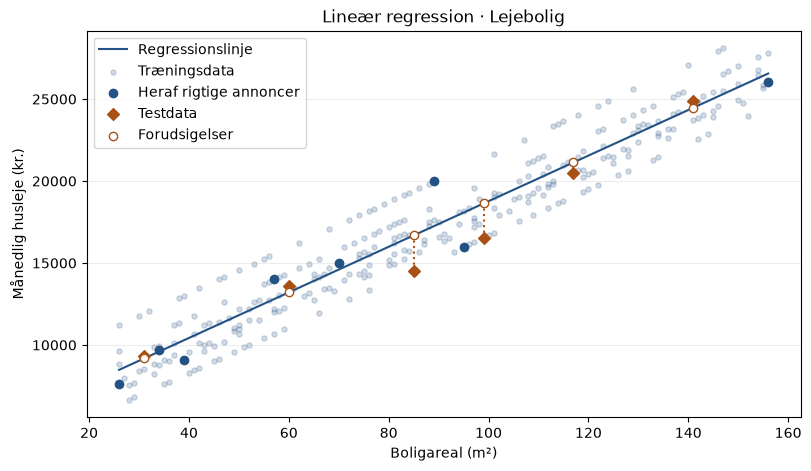

In [5]:
import matplotlib.pyplot as plt

train_values = [value for (value,) in X_train]
test_values = [value for (value,) in X_test]
real_train = [row for row in train if row["data_type"] == "real"]
line_values = [min(train_values), max(train_values)]
line_predictions = model.predict([[value] for value in line_values])

fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
ax.plot(line_values, line_predictions, color="#245285", label="Regressionslinje")
ax.scatter(train_values, y_train, color="#245285", alpha=0.2, s=14, label="Træningsdata")
ax.scatter([float(row["area_m2"]) for row in real_train],
           [float(row["monthly_rent_dkk"]) for row in real_train],
           color="#245285", zorder=3, label="Heraf rigtige annoncer")
ax.scatter(test_values, y_test, color="#a95015", marker="D", zorder=3, label="Testdata")
ax.scatter(test_values, predictions, facecolors="white", edgecolors="#a95015",
           zorder=3, label="Forudsigelser")
ax.vlines(test_values, predictions, y_test, colors="#a95015", linestyles="dotted")
ax.set(title="Lineær regression · Lejebolig", xlabel='Boligareal (m²)', ylabel='Månedlig husleje (kr.)')
ax.grid(axis="y", alpha=0.24)
ax.legend()
plt.show()